# Phase 2 — How each asset's variance behaves

**Goal.** Before choosing any forecasting model, learn how variance behaves. Is it predictable? How long is its memory? Do bad days raise future risk more than good days? And the make-or-break question: does the reward per unit of risk fall when risk is high? Ten tests, **development sample only (1926–2018)**. The 2019+ holdout is never loaded in this notebook.

### Key findings

1. **Variance is predictable for every asset** (Test 1, the gate: 8 of 8 pass). Monthly AR(1) slopes are 0.54–0.76.
2. **Memory is long** (Tests 2 and 10A). Autocorrelation of |r| is still 0.14–0.23 at lag 100. Weekly and monthly HAR terms are significant for 6 of 8 assets, and out-of-sample accuracy keeps rising up to 66 days of history for all 8. → **HAR family, with a 66-day term.**
3. **Reward per unit of risk falls with risk for market, momentum, BAB and the equal-weight portfolio** (Test 4: 4 of 8 pass). Momentum's Sharpe ratio is 1.57 after the calmest months and −0.05 after the wildest. Size and investment show no such pattern; value and profitability are borderline. **This is where volatility timing can work.**
4. **Bad days predict more risk only for value** (Test 3). Downside-variance models are a candidate for value and the market, not a general upgrade.
5. **VIX adds information for market, value, momentum and BAB; event days do not have clearly higher variance for any asset** (Test 5). → HAR-X with VIX for those four; no event flags.
6. **Patterns shift across eras** (Tests 6 and 10B). Rolling persistence drifts for all 8 assets, and the mean of log variance has breaks for 7 of 8. → **rolling windows and yearly re-screening.** Persistence and the falling reward-to-risk of market, momentum and BAB hold in every era once one extreme month (October 1987) is understood.
7. **Log variance is much closer to normal than variance but misses the pre-set threshold** (Test 7). Logs are the better-behaved scale; log vs level forecasts are compared out of sample in Phase 6.
8. **Collinearity is mild** (Test 8: highest VIF 4.6) and **curvature appears for 4 of 8 assets** (Test 9). Standard HAR terms are fine; the boosting model (M7) stays a candidate only for market, value, profitability and investment.
9. **History explains roughly 15–60% of next month's variance out of sample** (Test 10C). That is the bar a fancier model must clear.

### How to read this notebook

Every test has the same four parts: **what and why**, the **rule** (fixed before any test was run), the **result** (table and plot), and the **decision** it feeds into later phases. Numbers quoted in the text refer to the build of 2026-10-07; the tables and plots are recomputed every time the notebook runs.

In [24]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FixedLocator, NullLocator, ScalarFormatter
from scipy import stats
from statsmodels.nonparametric.smoothers_lowess import lowess

from src.config import ETFS
from src.data.load import load_dev, load_etf_ohlc_dev
from src import variance as v

pd.set_option("display.float_format", "{:,.3f}".format, "display.max_columns", 30, "display.width", 200)

NAMES = {"mkt": "Market", "smb": "Size", "hml": "Value", "mom": "Momentum", "rmw": "Profitability",
         "cma": "Investment", "bab": "Betting against beta", "ew7": "Equal-weight 7"}
COLORS = dict(zip(v.ASSETS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                             "#e87ba4", "#008300", "#4a3aa7", "#e34948"]))
ERA_COLORS = ["#86b6ef", "#2a78d6", "#104281"]          # one hue, light to dark: eras are ordered in time
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "lines.linewidth": 1.5, "font.size": 8.5, "axes.titlesize": 9.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})

def grid(nrows, ncols, w=2.1, h=1.8, **kw):
    return plt.subplots(nrows, ncols, figsize=(ncols * w, nrows * h), squeeze=False, **kw)

panel = load_dev()                                  # development sample only
R = v.daily_returns(panel)                          # daily excess returns: 7 factors + ew7
M = {a: v.monthly_table(R[a]) for a in v.ASSETS}    # monthly return, RV, RV-, RV+, log RV
print(f"Development sample: {panel.index[0].date()} to {panel.index[-1].date()}, {len(panel):,} trading days")

Development sample: 1926-07-01 to 2018-12-31, 24,391 trading days


## 1. Data

| code | asset | daily data from |
|---|---|---|
| `mkt` | Market excess return (Mkt-RF) | 1926-07 |
| `smb` | Size (small minus big) | 1926-07 |
| `hml` | Value (high minus low book-to-market) | 1926-07 |
| `mom` | Momentum (winners minus losers) | 1926-11 |
| `rmw` | Profitability (robust minus weak) | 1963-07 |
| `cma` | Investment (conservative minus aggressive) | 1963-07 |
| `bab` | Betting against beta (AQR) | 1930-12 |
| `ew7` | All seven, equally weighted, rebalanced daily | 1963-07 |

`ew7` stands in for the *diversified factor portfolio* the strategy will time. Its real weights are chosen in a later phase, so treat its results as illustrative.

Returns are daily excess returns. Monthly returns compound the daily ones. The factor ETFs (MTUM, QUAL, USMV) have only 5–7 development years, about 60–90 months. That is too few for monthly tests, where each quintile would hold 12–18 months. They appear in one section only: whether the high-low range is a better daily variance input (Section 14).

In [25]:
pd.DataFrame({a: {"asset": NAMES[a], "first month": str(M[a].index[0]), "last month": str(M[a].index[-1]),
                  "months": len(M[a]), "trading days": int(R[a].notna().sum())} for a in v.ASSETS}).T

,asset,first month,last month,months,trading days
mkt,Market,1926-07,2018-12,1110,24391
smb,Size,1926-07,2018-12,1110,24391
hml,Value,1926-07,2018-12,1110,24391
mom,Momentum,1926-11,2018-12,1106,24290
rmw,Profitability,1963-07,2018-12,666,13971
cma,Investment,1963-07,2018-12,666,13971
bab,Betting against beta,1930-12,2018-12,1057,23082
ew7,Equal-weight 7,1963-07,2018-12,666,13971


## 2. Decision rules (fixed before any test was run)

Phase 2 rule: *write each decision rule before looking*, because a rule written after seeing the plot bends to fit it. The thresholds below are the `RULES` constants in `src/variance.py`. They were written before the first test ran and have not changed since.

| Test | Pass rule | If it passes | If it fails |
|---|---|---|---|
| 1 Predictable (gate) | Ljung-Box on $r^2$ rejects at 1% at 20 **and** 60 lags, **and** monthly AR(1) slope φ > 0.5 | asset stays a timing candidate | no forecast, no strategy for that asset |
| 2 Memory | in the d+w+m regression, $\beta_w$ and $\beta_m$ both > 0 with Newey-West t > 1.96 | long memory → HAR family | short memory → EWMA / GARCH is enough |
| 3 Bad days | δ > 0 with Newey-West t > 1.96 | GJR-GARCH / downside HAR are candidates | symmetric models |
| 4 Reward vs risk | $\bar r/s^2$ lower in the wildest quintile than the calmest, rank correlation with quintile ≤ −0.7, **and** spanning α > 0 with White t > 1.96 | timing can add value | timing cannot earn alpha, however good the forecast |
| 5 Events / VIX | event: mean $r^2$ ≥ 1.2× other days and t > 1.96. VIX: t > 1.96 and R² gain ≥ 0.01 | add that input (HAR-X) | leave it out |
| 6 Eras | φ, $\beta_w+\beta_m$, δ and α each: every era has the full-sample sign and at least ⅓ of its size | the pattern is structural | the pattern is era-specific |
| 7 Shape | log RV: abs skewness < 0.5 and kurtosis < 4 (normal = 3) | forecast in logs | compare log and level forecasts out of sample |
| 8 Collinearity | any VIF > 10 is severe | non-overlapping HAR terms or ridge | standard HAR terms |
| 9 Curvature | quadratic term *c*, or the slope shift in the top 20% of months, has Newey-West abs t > 1.96 | keep M7 for its out-of-sample test | drop M7 |
| 10A History | history helps until a stage adds less than 0.5 point of out-of-sample R² | | |
| 10B Stability | rolling 10-year φ outside its 95% band in > 20% of windows, **or** CUSUM rejects a stable mean at 5% | rolling windows, yearly re-screening | an expanding window is fine |

**Conventions.** "Significant" means abs t > 1.96, the 5% two-sided threshold. Newey-West uses 44 lags for daily regressions with 22-day overlapping targets (the spec asks for at least 22) and 6 lags for monthly regressions. White standard errors are HC0.

**Many tests.** Ten tests on eight assets give about 80 verdicts, so a few will pass or fail by chance. Read the pattern across assets and eras, and the size of each effect, more than any single p-value.

**Transparency.** Two explanation checks were added *after* seeing results: October 1987 in Test 6, and the August 2015 ETF dislocation in Section 14. Both are labelled, and neither changes a verdict.

In [26]:
pd.Series(v.RULES, name="threshold").to_frame()

,threshold
t1_ljung_box_p,0.010
t1_phi,0.500
t,1.960
t4_spearman,-0.700
t5_event_ratio,1.200
t5_vix_dr2,0.010
t6_min_share,0.333
t7_log_skew,0.500
t7_log_kurt,4.000
t8_vif,10.000


## 3. Step 1 — The variance series

**Monthly realized variance** sums the month's squared daily returns ($N_t$ ≈ 21 trading days):
$$RV_t = \sum_{d=1}^{N_t} r_{t,d}^2$$

**Downside realized variance** counts the bad days only (Wang and Yan 2021):
$$RV_t^{-} = \sum_{d=1}^{N_t} r_{t,d}^2\,\mathbf{1}\{r_{t,d} < 0\}$$
If a month has fewer than three down days, the window extends back one month, because two squared returns make a useless estimate. **Upside variance** $RV_t^{+}$ is the rest of the month's variance.

**Log RV.** $RV_t$ is heavily right-skewed, so a few crisis months would dominate any regression in levels. $\log RV_t$ is far better behaved (Test 7).

**Parkinson range (ETFs only).** The French factors are paper portfolios with no high or low prices, so they use $r_t^2$. ETFs have intraday highs and lows, which give a daily variance estimate that should be much less noisy:
$$\hat{\sigma}_{P,t}^2 = \frac{(\ln H_t - \ln L_t)^2}{4\ln 2}$$

In [27]:
pd.DataFrame({a: {"average annual volatility": np.sqrt(12 * M[a]["rv"].mean()),
                  "share of RV from down days (median month)": ((M[a]["rv"] - M[a]["rv_up"]) / M[a]["rv"]).median(),
                  "months with < 3 down days (window extended)": int(M[a]["extended"].sum())}
              for a in v.ASSETS}).T

,average annual volatility,share of RV from down days (median month),months with < 3 down days (window extended)
mkt,0.172,0.462,2.000
smb,0.095,0.513,8.000
hml,0.095,0.472,3.000
mom,0.121,0.463,5.000
rmw,0.059,0.454,4.000
cma,0.057,0.482,1.000
bab,0.098,0.433,4.000
ew7,0.029,0.382,21.000


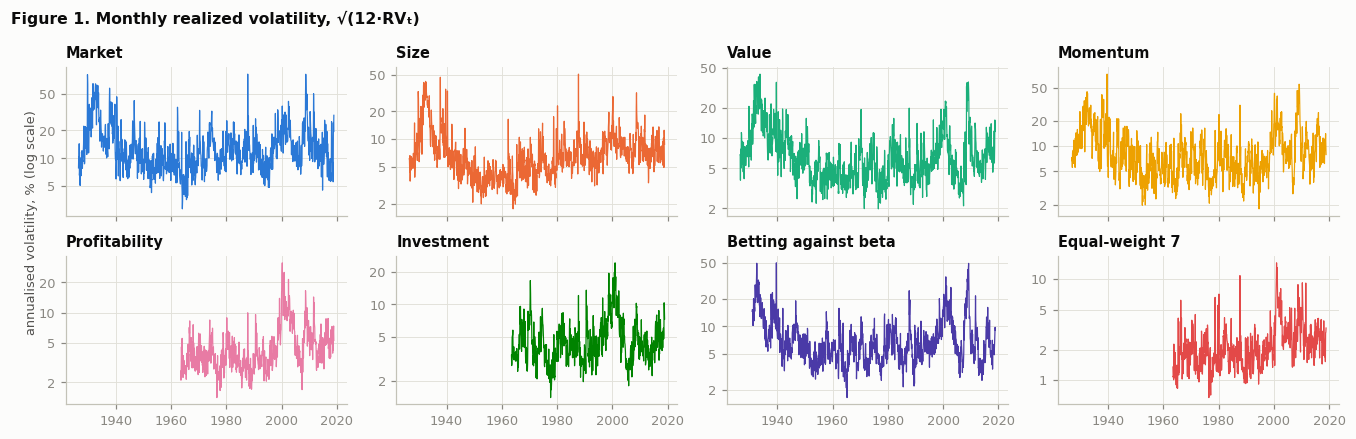

In [28]:
fig, ax = grid(2, 4, w=3.1, h=2.0, sharex=True)
for a, axi in zip(v.ASSETS, ax.flat):
    m = M[a]
    axi.plot(m.index.to_timestamp(), np.sqrt(12 * m["rv"]) * 100, color=COLORS[a], lw=0.8)
    axi.set_yscale("log"); axi.set_title(NAMES[a])
    axi.yaxis.set_major_locator(FixedLocator([1, 2, 5, 10, 20, 50, 100]))
    axi.yaxis.set_major_formatter(ScalarFormatter()); axi.yaxis.set_minor_locator(NullLocator())
fig.supylabel("annualised volatility, % (log scale)", fontsize=8.5, color=INK2)
fig.suptitle("Figure 1. Monthly realized volatility, √(12·RVₜ)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

**Reading.**
- **Volatility comes in runs.** High months cluster: 1929–1933, 1937–38, 1987, 2000–2002 and 2008–09 stand out. Clustering is what makes variance forecastable.
- **Levels differ a lot across assets.** The market averages 17% a year. Profitability and investment average about 6%. The equal-weight portfolio averages only 3%, because the seven factors are only loosely correlated. Each asset is therefore timed on its own scale.
- **Down days supply about half of each month's variance** (38–51%), so downside RV carries roughly half the data of total RV. The Wang-Yan window extension is rarely needed: 1–8 months per factor. The calm, upward-drifting equal-weight portfolio needs it in 21 months.

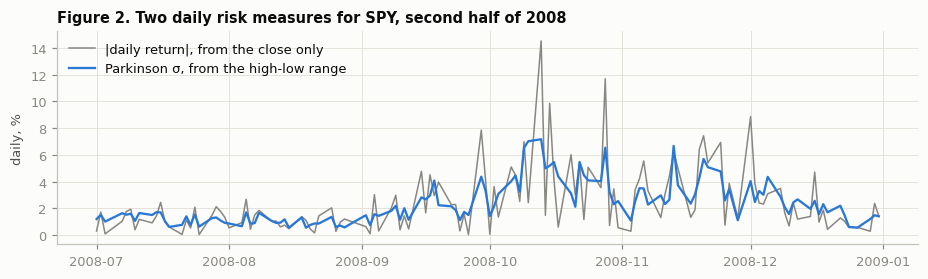

In [29]:
ohlc_dev = load_etf_ohlc_dev()
park_spy = v.parkinson(ohlc_dev, "SPY")
d = pd.DataFrame({"|r|": panel["spy"].abs(), "Parkinson σ": np.sqrt(park_spy)}).loc["2008-07":"2008-12"] * 100
fig, axi = plt.subplots(figsize=(8.5, 2.6))
axi.plot(d.index, d["|r|"], color=MUTED, lw=1.0, label="|daily return|, from the close only")
axi.plot(d.index, d["Parkinson σ"], color=COLORS["mkt"], lw=1.5, label="Parkinson σ, from the high-low range")
axi.set_ylabel("daily, %"); axi.legend(loc="upper left")
axi.set_title("Figure 2. Two daily risk measures for SPY, second half of 2008")
fig.tight_layout()

**Reading.** The close-to-close measure swings between near-zero and very large from one day to the next. A day that ends near where it opened looks calm even if it swung widely in between. The range measure sees the swing, so it moves far more smoothly. One limitation: the range misses the overnight gap, so for SPY it averages 73% of $r^2$. Section 14 tests whether the smoother measure really forecasts better.

## 4. Test 1 — Is variance predictable? (the gate)

**What and why.** If today's variance says nothing about next month's, there is nothing to forecast and no strategy. Two checks:

- **Ljung-Box on squared daily returns** at 20 and 60 lags. Here $\hat\rho_k$ is the lag-*k* autocorrelation of $r^2$. With no autocorrelation, *Q* follows a χ² distribution with *m* degrees of freedom:
$$Q = n(n+2)\sum_{k=1}^{m}\frac{\hat{\rho}_k^2}{n-k}$$
- **AR(1) on non-overlapping monthly realized variance:**
$$RV_{t+1} = \phi_0 + \phi\,RV_t + u_{t+1}$$
The months must not overlap: overlapping windows share days, so they look sticky even when they are not.

**Rule.** Ljung-Box rejects at 1% at both lags **and** φ > 0.5.

Also reported, outside the rule: φ on log RV, the R², and a replication of Barroso and Santa-Clara (2015) on their 1963–2011 window. Their figures: market 0.58, value 0.73, momentum 0.77, size 0.33.

,months,Q20,p20,Q60,p60,phi,phi_se,phi_log,R2,pass
mkt,1109,"13,111.058",0.000,"21,116.242",0.000,0.621,0.024,0.736,0.385,pass
smb,1109,"11,479.505",0.000,"21,407.325",0.000,0.595,0.024,0.771,0.354,pass
hml,1109,"13,802.223",0.000,"32,565.443",0.000,0.726,0.021,0.786,0.526,pass
mom,1105,"5,607.570",0.000,"10,548.467",0.000,0.535,0.025,0.778,0.287,pass
rmw,665,"27,145.543",0.000,"55,017.474",0.000,0.761,0.025,0.782,0.579,pass
cma,665,"8,090.423",0.000,"18,124.436",0.000,0.681,0.028,0.743,0.464,pass
bab,1056,"22,579.499",0.000,"43,200.907",0.000,0.668,0.023,0.805,0.446,pass
ew7,665,"11,013.737",0.000,"20,834.645",0.000,0.604,0.031,0.667,0.365,pass


,"φ here, 1963-2011",φ Barroso & Santa-Clara
mkt,0.533,0.580
hml,0.744,0.730
mom,0.707,0.770
smb,0.284,0.330


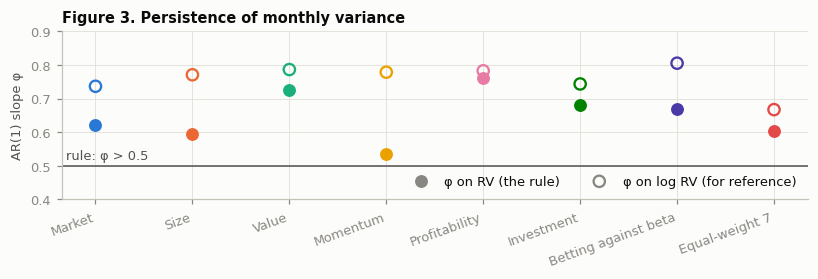

In [30]:
T1 = pd.DataFrame({a: v.t1_persistence(R[a], M[a]) for a in v.ASSETS}).T
T1["pass"] = T1["pass"].map({True: "pass", False: "fail"})
display(T1[["months", "Q20", "p20", "Q60", "p60", "phi", "phi_se", "phi_log", "R2", "pass"]])

bsc = {"mkt": 0.58, "hml": 0.73, "mom": 0.77, "smb": 0.33}
rep = pd.DataFrame({a: {"φ here, 1963-2011": v.t1_persistence(R[a].loc["1963":"2011"], M[a].loc["1963":"2011"])["phi"],
                        "φ Barroso & Santa-Clara": bsc[a]} for a in bsc}).T
display(rep)

fig, axi = plt.subplots(figsize=(7.5, 2.6))
x = np.arange(len(v.ASSETS))
for i, a in enumerate(v.ASSETS):
    axi.scatter(i, T1.loc[a, "phi"], s=55, color=COLORS[a], zorder=3)
    axi.scatter(i, T1.loc[a, "phi_log"], s=55, facecolor="none", edgecolor=COLORS[a], lw=1.5, zorder=3)
axi.axhline(v.RULES["t1_phi"], color=INK2, lw=1)
axi.text(-0.3, v.RULES["t1_phi"] + 0.01, "rule: φ > 0.5", ha="left", va="bottom", color=INK2)
axi.scatter([], [], s=55, color=MUTED, label="φ on RV (the rule)")
axi.scatter([], [], s=55, facecolor="none", edgecolor=MUTED, lw=1.5, label="φ on log RV (for reference)")
axi.set_xticks(x, [NAMES[a] for a in v.ASSETS], rotation=20, ha="right")
axi.set_ylim(0.4, 0.9); axi.set_ylabel("AR(1) slope φ"); axi.legend(loc="lower right", ncol=2)
axi.set_title("Figure 3. Persistence of monthly variance")
fig.tight_layout()

**Result.** **All eight assets pass the gate.**
- **Ljung-Box:** the Q statistics run into the thousands (p ≈ 0). With about 24,000 days the test rejects for any real persistence, so the size of φ is the informative number.
- **Persistence:** φ runs from 0.54 (momentum) to 0.76 (profitability). In logs it is higher and more uniform (0.67–0.81), because the level regression is pulled down by isolated spike months that revert at once (see Test 6).
- **Replication over 1963–2011:** market 0.53 vs 0.58 published, value 0.74 vs 0.73, momentum 0.71 vs 0.77, size 0.28 vs 0.33. The values are close. The gap for momentum is plausibly construction: Barroso and Santa-Clara build their own top-minus-bottom decile portfolio, while French's comes from broader 2×3 sorts.

Persistence is necessary, not sufficient. Value is among the stickiest assets here (0.73) yet gains little from timing in Test 4, which is exactly the warning from Cederburg et al.

**Decision.** All eight remain timing candidates.

## 5. Test 2 — How fast does persistence decay?

**What and why.** This test picks the model family. If persistence dies out within days, a short-memory model (EWMA, GARCH) is enough. If it lingers for months, weekly and monthly averages carry information beyond today's return, and the HAR model is built for exactly that.

**Two looks.**
1. **Autocorrelation** of squared and absolute daily returns out to lag 100, plus the **partial** autocorrelation (PACF, which Test 7 asks for). The PACF shows the direct effect of lag *k* after removing the lags in between.
2. **Nested regressions** forecasting the average daily variance over the next 22 days:
$$\overline{RV}_{t+1:t+22} = \beta_0 + \beta_d\,RV_t^{(d)} + \beta_w\,RV_t^{(w)} + \beta_m\,RV_t^{(m)} + \varepsilon_{t+22}$$
   - $RV^{(d)}_t = r_t^2$ is today's squared return; $RV^{(w)}_t$ and $RV^{(m)}_t$ average the last 5 and 22 days.
   - The model starts with the daily term alone, then adds weekly, then monthly.
   - **Newey-West standard errors, 44 lags.** The 22-day targets overlap, so the errors are autocorrelated and plain OLS standard errors come out far too small.

**Rule.** Long memory if $\beta_w$ **and** $\beta_m$ are both positive with t > 1.96.

acf r²                         acf |r|                         pacf r²                           
lag    1     5     22    66    100     1     5     22    66    100     1     5      22     66     100
mkt  0.235 0.224 0.104 0.070 0.051   0.292 0.305 0.216 0.162 0.145   0.235 0.128  0.019  0.011 -0.011
smb  0.338 0.184 0.102 0.084 0.084   0.390 0.326 0.256 0.212 0.213   0.338 0.104  0.018  0.005 -0.002
hml  0.233 0.200 0.139 0.135 0.113   0.374 0.335 0.261 0.246 0.231   0.233 0.117  0.024  0.009 -0.003
mom  0.155 0.145 0.083 0.056 0.052   0.387 0.348 0.266 0.215 0.201   0.155 0.108  0.020 -0.001  0.005
rmw  0.326 0.331 0.238 0.184 0.141   0.372 0.345 0.309 0.263 0.229   0.326 0.144 -0.018  0.017  0.026
cma  0.187 0.159 0.118 0.135 0.109   0.279 0.258 0.198 0.196 0.161   0.187 0.074  0.003  0.009  0.033
bab  0.258 0.289 0.174 0.131 0.119   0.370 0.356 0.290 0.251 0.225   0.258 0.183  0.014  0.005 -0.008
ew7  0.257 0.263 0.140 0.133 0.100   0.342 0.322 0.216 0.185 0.164   0.257 0.173  0.026  0.017  0.030

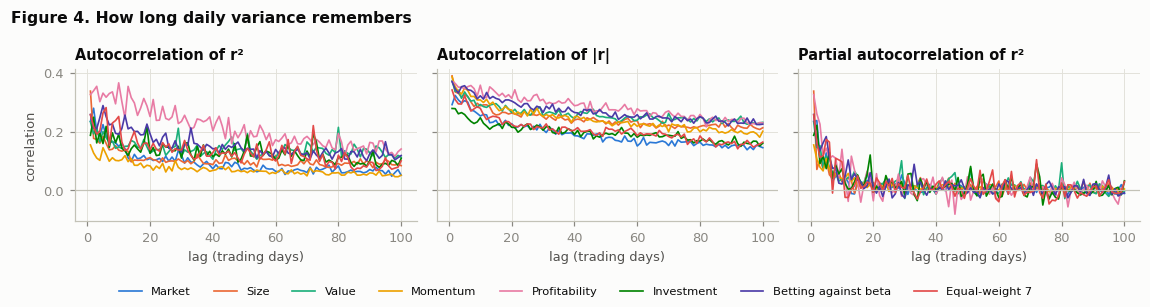

In [31]:
AC = {a: v.autocorrelations(R[a]) for a in v.ASSETS}
fig, ax = grid(1, 3, w=3.5, h=2.7, sharey=True)
for j, col in enumerate(["acf r²", "acf |r|", "pacf r²"]):
    for a in v.ASSETS:
        ax[0, j].plot(AC[a].index, AC[a][col], color=COLORS[a], lw=1.1, label=NAMES[a])
    ax[0, j].axhline(0, color=AXIS, lw=0.8); ax[0, j].set_xlabel("lag (trading days)")
    ax[0, j].set_title({"acf r²": "Autocorrelation of r²", "acf |r|": "Autocorrelation of |r|",
                        "pacf r²": "Partial autocorrelation of r²"}[col])
ax[0, 0].set_ylabel("correlation")
h, l = ax[0, 0].get_legend_handles_labels()
fig.suptitle("Figure 4. How long daily variance remembers", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.legend(h, l, loc="lower center", ncol=8, fontsize=7.5)

lags = [1, 5, 22, 66, 100]
display(pd.concat({col: pd.DataFrame({a: AC[a][col].loc[lags] for a in v.ASSETS}).T
                   for col in ["acf r²", "acf |r|", "pacf r²"]}, axis=1).rename_axis(columns=["", "lag"]))

In [32]:
T2 = pd.DataFrame({a: v.t2_har(R[a]) for a in v.ASSETS}).T
T2["verdict"] = T2["long_memory"].map({True: "long memory", False: "short memory"})
T2.drop(columns="long_memory")

,R2 d,R2 d+w,R2 d+w+m,b_d,t_d,b_w,t_w,b_m,t_m,verdict
mkt,0.107,0.235,0.312,0.028,2.773,0.125,3.430,0.393,4.548,long memory
smb,0.098,0.210,0.312,0.031,3.820,0.080,2.064,0.440,6.128,long memory
hml,0.125,0.315,0.479,0.017,3.300,0.064,2.268,0.608,9.800,long memory
mom,0.069,0.205,0.316,0.011,1.357,0.083,1.536,0.462,4.440,short memory
rmw,0.268,0.549,0.622,0.018,2.503,0.239,3.945,0.519,4.731,long memory
cma,0.126,0.326,0.478,0.013,1.581,0.085,1.797,0.590,5.573,short memory
bab,0.176,0.431,0.511,0.013,2.705,0.209,4.037,0.478,4.906,long memory
ew7,0.147,0.357,0.437,0.018,2.073,0.186,4.940,0.443,6.030,long memory


**Result.**
- **The autocorrelations decay slowly.** For |r| they start at 0.28–0.39 at lag 1 and are still 0.14–0.23 at lag 100. A GARCH(1,1) implies geometric decay, which would be near zero long before lag 100. For r² the decay is faster (0.05–0.14 at lag 100), because squares are dominated by a few extreme days. That makes |r| the clearer view of memory.
- **The PACF is near zero after about a week** (≤ 0.03 at lag 22). No single old day matters much on its own. The long memory comes from many small effects adding up, which is exactly what the HAR's weekly and monthly averages capture with only three coefficients.
- **The regressions:** R² rises from 0.07–0.27 with today's squared return alone to 0.31–0.62 with all three terms. The monthly term is the strongest (t 4.4–9.8).
- **Verdict:** long memory for 6 of 8 assets. Momentum and investment miss the rule only because their weekly term's t is 1.54 and 1.80; their monthly term is highly significant (t 4.4 and 5.6).

**Decision.** The HAR family for market, size, value, profitability, BAB and the equal-weight portfolio. For momentum and investment the rule says EWMA/GARCH may be enough. Their strong monthly term, and Test 10A, where longer history keeps improving out-of-sample forecasts, point the other way. Both families go to the out-of-sample comparison for those two.

## 6. Test 3 — Do bad days raise future risk more than good days?

**What and why.** In stock indices, a fall raises future volatility more than a rise of the same size (the "leverage effect"). If that holds here, downside variance is the sharper signal and asymmetric models (GJR-GARCH, downside HAR) should beat symmetric ones.
$$\overline{RV}_{t+1:t+22} = k_0 + k_1\,r_t^2 + \delta\,r_t^2\,\mathbf{1}\{r_t < 0\} + \varepsilon_{t+22}$$
δ is the *extra* future variance per unit of today's squared return when today was a loss.

**The return side.** Next month's return is regressed on this month's downside and upside variance, with White standard errors. Wang and Yan trace the edge of downside scaling to return timing: if downside variance predicts lower returns and upside variance does not, scaling by downside variance cuts exposure just before poor returns.

**Rule.** δ > 0 with Newey-West t > 1.96. The return side is reported but has no pass rule.

**Plot.** A "news impact curve": future 22-day volatility against today's return, in 20 bins. A symmetric V means no asymmetry; a higher left arm means bad days raise risk more.

,k1,t_k1,delta,t_delta,pass,b_down,t_down,b_up,t_up
mkt,0.124,4.796,0.055,1.058,fail,-3.374,-2.087,3.306,1.258
smb,0.189,3.757,-0.070,-1.120,fail,0.267,0.141,-0.555,-0.173
hml,0.129,5.091,0.135,4.272,pass,-10.070,-2.114,9.870,2.445
mom,0.289,9.331,-0.211,-4.306,fail,-1.407,-0.993,-8.007,-2.499
rmw,0.304,7.199,0.006,0.129,fail,0.924,0.059,9.769,1.247
cma,0.281,6.705,-0.171,-3.167,fail,9.674,1.034,8.071,1.085
bab,0.204,6.100,0.021,0.370,fail,-2.337,-0.607,5.724,1.547
ew7,0.339,5.034,-0.200,-2.884,fail,17.122,1.003,-3.617,-0.127


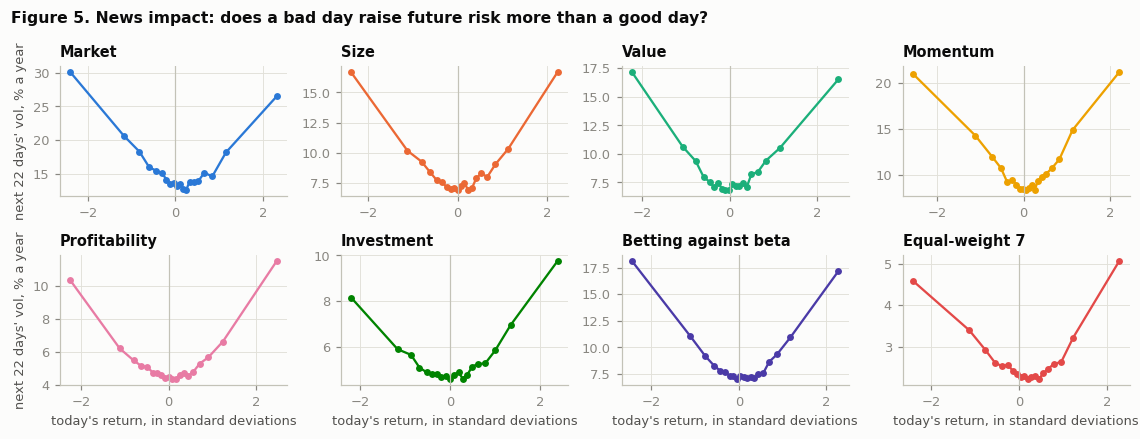

In [33]:
T3 = pd.DataFrame({a: {**v.t3_asymmetry(R[a]), **v.t3_return_side(M[a])} for a in v.ASSETS}).T
T3["pass"] = T3["pass"].map({True: "pass", False: "fail"})
display(T3[["k1", "t_k1", "delta", "t_delta", "pass", "b_down", "t_down", "b_up", "t_up"]])

def news_impact(r, bins=20):
    r = r.dropna()
    df = pd.DataFrame({"z": r / r.std(), "y": (r ** 2).rolling(22).mean().shift(-22)}).dropna()
    g = df.groupby(pd.qcut(df["z"], bins, labels=False)).mean()
    return g["z"], np.sqrt(252 * g["y"]) * 100

fig, ax = grid(2, 4, w=2.6, h=2.0)
for a, axi in zip(v.ASSETS, ax.flat):
    z, vol = news_impact(R[a])
    axi.plot(z, vol, color=COLORS[a], marker="o", ms=3.5)
    axi.axvline(0, color=AXIS, lw=0.8); axi.set_title(NAMES[a])
for axi in ax[1]:
    axi.set_xlabel("today's return, in standard deviations")
for axi in ax[:, 0]:
    axi.set_ylabel("next 22 days' vol, % a year")
fig.suptitle("Figure 5. News impact: does a bad day raise future risk more than a good day?",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

**Result.**
- **Only value passes** (δ t = 4.3). In Figure 5 the difference is hard to see: the regression is driven by the most extreme days, which the outer bins average away.
- **Market:** δ is positive but not significant (t = 1.06). Its curve sits only a little higher on the left (30% vs 27% future volatility after the worst and best days). Over 1926–2018, with factor returns rather than an index, the leverage effect is weaker than in index-level studies.
- **Momentum (t = −4.3), investment (−3.2) and the equal-weight portfolio (−2.9):** δ is significantly *negative*. After their good days, future variance is higher; for investment and the equal-weight portfolio the right arm of the curve is visibly higher. For momentum this fits the known crash pattern: its worst spells come in violent market rebounds, when both its gains and losses are large.
- **The return side** separates the two kinds of variance for the market and value:
  - **Market:** downside variance predicts *lower* next-month returns (t = −2.1), and upside variance predicts higher ones (t = +1.3).
  - **Value:** the same pattern, stronger (t = −2.1 and +2.4).
  - **Momentum:** the reverse. Upside variance predicts lower returns (t = −2.5).

**Decision.** Downside-variance models (downside HAR, GJR-GARCH) are a candidate for value, which passes on both channels, and for the market, through the return channel only. They are not a default upgrade, and for momentum they would point the wrong way. Elsewhere, symmetric models.

## 7. Test 4 — Does reward per unit of risk fall when risk is high?

**What and why.** This is the make-or-break test; it mirrors Figure 1 of Moreira and Muir. Volatility timing earns alpha only if expected return does *not* rise in step with variance when variance is high. Then the reward per unit of risk, $\bar r/s^2$, falls as risk rises, and cutting exposure in high-variance times improves the trade-off. ($\bar r/s^2$ is proportional to the optimal mean-variance weight.) If $\bar r/s^2$ is flat, the alpha is zero however good the variance forecast.

1. Sort development months into five groups by this month's realized variance.
2. In each group, compute **next** month's mean return $\bar r$, variance $s^2$, and $\bar r/s^2$ (annualised), plus the Sharpe ratio.
3. Run the **spanning regression** with White standard errors, because return variance changes over time by design:
$$\frac{c}{RV_t}\,r_{t+1} = \alpha + \beta\,r_{t+1} + \varepsilon_{t+1}$$

*c* is set so the managed and unmanaged returns have the same volatility. Using one full-sample *c* is fine here: scaling *c* scales α and its standard error equally, so the t-statistic does not depend on it. The *level* of α is in-sample, so this is a screen, not proof.

**Rule.** $\bar r/s^2$ is lower in the wildest group than the calmest, its rank correlation with the group number is ≤ −0.7, **and** α > 0 with t > 1.96.

,Sharpe calmest,Sharpe wildest,variance wildest / calmest,spearman,alpha,t_alpha,beta,pass
mkt,0.749,0.240,8.081,-0.900,0.048,3.224,0.620,pass
smb,-0.016,0.331,6.021,0.600,-0.006,-0.735,0.648,fail
hml,0.242,0.413,10.516,-0.600,0.015,1.616,0.567,fail
mom,1.570,-0.046,16.483,-0.900,0.104,7.612,0.500,pass
rmw,0.796,0.354,9.588,-0.600,0.024,3.016,0.593,fail
cma,0.405,0.846,5.704,0.000,0.002,0.263,0.685,fail
bab,1.611,0.352,12.894,-1.000,0.066,6.538,0.591,pass
ew7,2.182,1.130,6.877,-0.900,0.019,3.855,0.637,pass


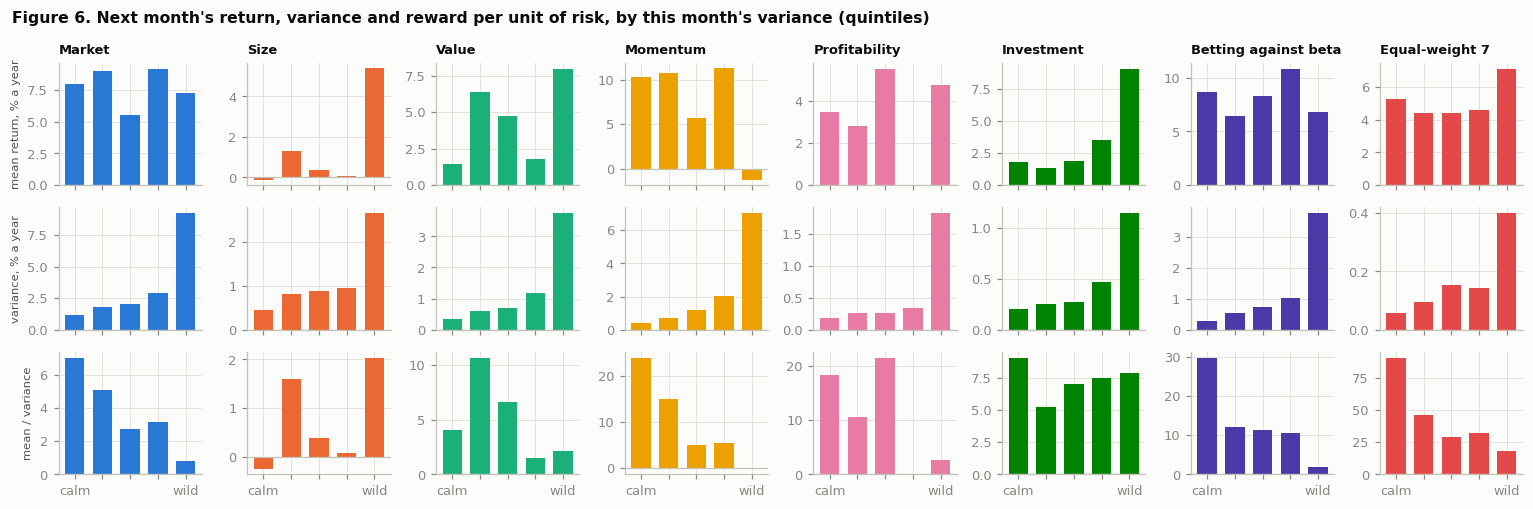

In [34]:
SORT = {a: v.t4_sort(M[a]) for a in v.ASSETS}
SPAN = {a: v.t4_spanning(M[a]) for a in v.ASSETS}
T4 = pd.DataFrame({a: {**SPAN[a], **v.t4_verdict(SORT[a], SPAN[a]),
                       "Sharpe calmest": SORT[a]["sharpe"].iloc[0], "Sharpe wildest": SORT[a]["sharpe"].iloc[-1],
                       "variance wildest / calmest": SORT[a]["var"].iloc[-1] / SORT[a]["var"].iloc[0]}
                   for a in v.ASSETS}).T
T4["pass"] = T4["pass"].map({True: "pass", False: "fail"})
display(T4[["Sharpe calmest", "Sharpe wildest", "variance wildest / calmest", "spearman",
            "alpha", "t_alpha", "beta", "pass"]])

fig, ax = grid(3, 8, w=1.75, h=1.55, sharex=True)
rows = [("mean", "mean return, % a year", 100), ("var", "variance, % a year", 100), ("ratio", "mean / variance", 1)]
for j, a in enumerate(v.ASSETS):
    for i, (col, lab, k) in enumerate(rows):
        axi = ax[i, j]
        axi.bar(range(1, 6), SORT[a][col] * k, color=COLORS[a], width=0.7)
        axi.axhline(0, color=AXIS, lw=0.8)
        if i == 0: axi.set_title(NAMES[a], fontsize=8.5)
        if j == 0: axi.set_ylabel(lab, fontsize=7.5)
        if i == 2: axi.set_xticks(range(1, 6), ["calm", "", "", "", "wild"])
fig.suptitle("Figure 6. Next month's return, variance and reward per unit of risk, by this month's variance (quintiles)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

**Result.** **Four assets pass: market, momentum, BAB and the equal-weight portfolio.**

- **The pattern for those four.** Variance climbs 7–16 times from the calmest to the wildest group. Mean return stays roughly flat, or falls. So reward per unit of risk drops sharply.
- **Sharpe ratio after calm vs wild months:** momentum 1.57 → −0.05, against 1.72 → 0.28 in Barroso and Santa-Clara; BAB 1.61 → 0.35; market 0.75 → 0.24.
- **Alpha** (annualised, in-sample): momentum 10.4% (t 7.6), BAB 6.6% (t 6.5), market 4.8% (t 3.2) and the equal-weight portfolio 1.9% (t 3.9). The last is small in percent, but that portfolio's volatility is only about 3% a year.

**Failures:**
- **Size:** α is −0.6%. Mean return is *highest* in the wildest group, so reward rises with risk.
- **Investment:** α is 0.2%, and the ratio is flat.
- **Value:** α is 1.5% (t 1.6), and the ratio peaks in the second group (rank correlation −0.6). Its variance is sticky, but timing gains little. This is Cederburg et al.'s point exactly.
- **Profitability:** α is 2.4% (t 3.0), but the sort is not monotone (the fourth group's mean is about zero, the third group's is high). It fails the pre-set rule and is borderline.

**Decision.** Volatility timing is promising for market, momentum, BAB and the diversified portfolio. Do not expect it to help size or investment: in the portfolio they are better held at constant weight. Value and profitability are borderline; the out-of-sample tests decide.

## 8. Test 5 — Do scheduled events and VIX add information?

**What and why.** Do inputs beyond past returns help?

- **Events.** Compare average $r^2$ on FOMC, CPI and jobs-report days with days that have none of them, over 1994–2018 (where the event calendar exists). The t-statistic comes from regressing $r^2$ on the three flags with Newey-West errors.
- **VIX.** Convert it to the daily variance it implies, $(\mathrm{VIX}/100)^2/252$, add it to the Test 2 regression (1990–2018), and check the R² gain and its Newey-West t. VIX measures S&P 500 option-implied risk, so for the other factors it is an outside signal to test, not to assume.

**Rule.** For an event: mean $r^2$ ≥ 1.2× other days with t > 1.96. For VIX: t > 1.96 and an R² gain ≥ 0.01.

**Calendar caveat.** Event flags only help with daily or weekly rebalancing. At monthly frequency nearly every month has one CPI and one jobs report, so the flag barely varies.

,fomc ratio,fomc t,cpi ratio,cpi t,jobs ratio,jobs t
mkt,1.010,0.033,1.086,0.556,1.113,0.959
smb,1.056,0.512,0.853,-1.575,0.852,-1.766
hml,1.144,0.618,1.231,1.088,0.973,-0.133
mom,0.959,-0.185,0.970,-0.132,0.861,-1.111
rmw,0.909,-0.602,0.902,-0.731,0.924,-0.444
cma,0.838,-1.191,0.748,-2.486,0.940,-0.484
bab,1.049,0.391,0.963,-0.292,1.017,0.169
ew7,0.819,-1.412,0.904,-0.808,1.014,0.100


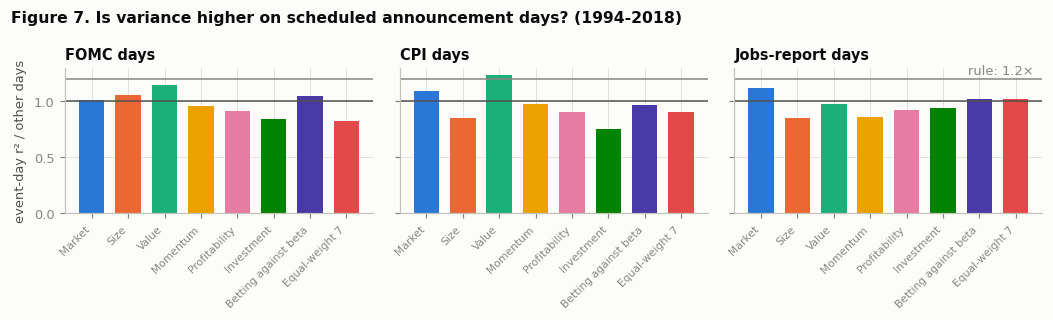

In [35]:
EV = {a: v.t5_events(R[a], panel) for a in v.ASSETS}
ev = pd.concat({a: EV[a][["ratio", "t"]].stack() for a in v.ASSETS}, axis=1).T
ev.columns = [f"{e} {k}" for e, k in ev.columns]
display(ev)

fig, ax = grid(1, 3, w=3.2, h=2.9, sharey=True)
for axi, e in zip(ax[0], v.EVENTS):
    axi.bar(range(len(v.ASSETS)), [EV[a].loc[e, "ratio"] for a in v.ASSETS],
            color=[COLORS[a] for a in v.ASSETS], width=0.7)
    axi.axhline(1, color=INK2, lw=1); axi.axhline(v.RULES["t5_event_ratio"], color=MUTED, lw=1)
    axi.set_xticks(range(len(v.ASSETS)), [NAMES[a] for a in v.ASSETS], rotation=45, ha="right", fontsize=7)
    axi.set_title({"fomc": "FOMC days", "cpi": "CPI days", "jobs": "Jobs-report days"}[e])
ax[0, 0].set_ylabel("event-day r² / other days")
ax[0, 2].text(len(v.ASSETS) - 0.5, v.RULES["t5_event_ratio"] + 0.01, "rule: 1.2×", ha="right", va="bottom", color=MUTED)
fig.suptitle("Figure 7. Is variance higher on scheduled announcement days? (1994-2018)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

In [36]:
T5 = pd.DataFrame({a: v.t5_vix(R[a], panel["vix"]) for a in v.ASSETS}).T
T5["pass"] = T5["pass"].map({True: "pass", False: "fail"})
T5

,R2 HAR,R2 HAR+VIX,dR2,b_vix,t_vix,pass
mkt,0.521,0.546,0.025,0.400,4.414,pass
smb,0.426,0.444,0.019,0.038,1.707,fail
hml,0.510,0.527,0.017,0.062,2.781,pass
mom,0.581,0.631,0.051,0.213,5.558,pass
rmw,0.607,0.607,0.000,0.003,0.437,fail
cma,0.478,0.482,0.004,0.009,1.575,fail
bab,0.586,0.656,0.070,0.183,5.436,pass
ew7,0.494,0.497,0.003,0.003,1.809,fail


**Result.**
- **Events: none passes, for any asset.** Market variance is 1.01× normal on FOMC days, 1.09× on CPI days and 1.11× on jobs-report days, and none of these is significant. Several factors are even *calmer* on announcement days. Over 1994–2018 a scheduled announcement did not, by itself, make factor returns noticeably more volatile that day. What moves markets is the size of the surprise, which a flag cannot measure.
- **VIX passes for four assets:** market (R² +2.5 points, t 4.4), value (+1.7, t 2.8), momentum (+5.1, t 5.6) and BAB (+7.0, t 5.4). For momentum and BAB it helps even more than for the market itself: option markets price a stress level that also hits those factors. VIX fails for size, profitability, investment and the equal-weight portfolio. (The HAR R² here is higher than in Test 2 because the sample is 1990–2018.)

**Decision.** In Phase 6, build HAR-X with VIX for market, value, momentum and BAB. Leave the event flags out.

## 9. Test 6 — Does it hold across eras?

**What and why.** A pattern that lives in one era is history, not a strategy. The headline number of Tests 1–4 is re-estimated in 1926–1962, 1963–1990 and 1991–2018. Profitability, investment and the equal-weight portfolio start in 1963, so they have two eras.

Headline numbers:
- **φ** (Test 1);
- **$\beta_w+\beta_m$** (Test 2): the total weight on the longer windows;
- **δ** (Test 3);
- **α** (Test 4), with *c* re-set within each era.

**Rule.** For each headline number, every era has the full-sample sign and at least one third of its size.

phi (T1)                               b_w+b_m (T2)                               delta (T3)                               alpha (T4)                              
era       full 1926-1962 1963-1990 1991-2018         full 1926-1962 1963-1990 1991-2018       full 1926-1962 1963-1990 1991-2018       full 1926-1962 1963-1990 1991-2018
asset                                                                                                                                                                    
bab      0.668     0.578     0.456     0.754        0.687     0.622     0.493     0.737      0.021     0.022     0.020     0.039      0.066     0.035     0.032     0.134
cma      0.681       NaN     0.579     0.687        0.675       NaN     0.577     0.681     -0.171       NaN    -0.091    -0.191      0.002       NaN     0.003    -0.005
ew7      0.604       NaN     0.073     0.664        0.629       NaN     0.141     0.677     -0.200       NaN     0.032    -0.204      0.019       NaN     0.010     0.032
hml      0.726     0.707     0.415     0.746        0.672     0.658     0.445     0.669      0.135     0.148    -0.093     0.051      0.015     0.004     0.009     0.004
mkt      0.621     0.670     0.156     0.708        0.518     0.489     0.224     0.692      0.055     0.122    -0.048     0.100      0.048     0.073     0.021     0.054
mom      0.535     0.381     0.321     0.708        0.545     0.362     0.370     0.739     -0.211    -0.196     0.013    -0.106      0.104     0.121     0.056     0.121
rmw      0.761       NaN     0.323     0.750        0.758       NaN     0.401     0.747      0.006       NaN     0.080    -0.007      0.024       NaN     0.014     0.029
smb      0.595     0.679     0.093     0.654        0.520     0.569     0.152     0.609     -0.070    -0.003    -0.170     0.011     -0.006    -0.012    -0.005    -0.004

,phi (T1),b_w+b_m (T2),delta (T3),alpha (T4)
mkt,not consistent,consistent,not consistent,consistent
smb,not consistent,not consistent,not consistent,consistent
hml,consistent,consistent,not consistent,not consistent
mom,consistent,consistent,not consistent,consistent
rmw,consistent,consistent,not consistent,consistent
cma,consistent,consistent,consistent,not consistent
bab,consistent,consistent,consistent,consistent
ew7,not consistent,not consistent,not consistent,consistent


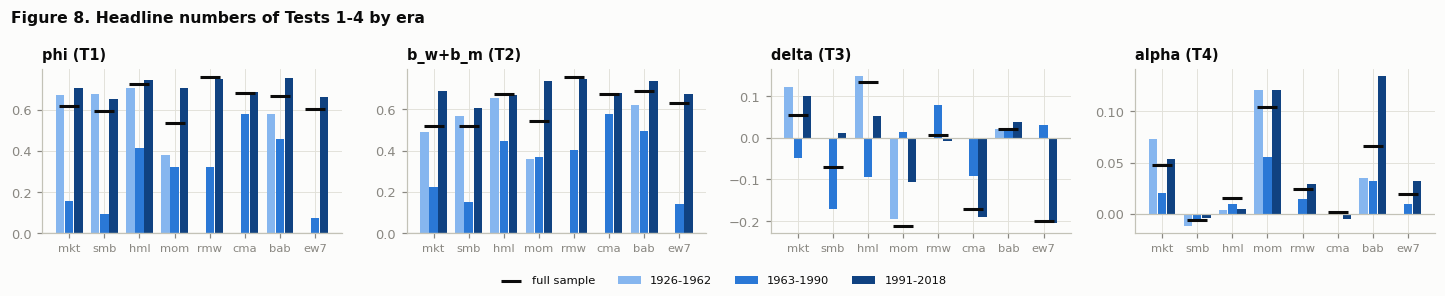

In [37]:
rows = []
for a in v.ASSETS:
    rows.append({"asset": a, "era": "full", **v.headline(R[a], M[a])})
    for era, (s, e) in v.SUBPERIODS.items():
        if len(M[a].loc[s:e]) >= 120:
            rows.append({"asset": a, "era": era, **v.headline(R[a].loc[s:e].dropna(), M[a].loc[s:e])})
T6 = pd.DataFrame(rows).set_index(["asset", "era"])
display(T6.unstack("era")[[(k, e) for k in T6.columns for e in ["full", *v.SUBPERIODS]]].round(3))

stat_cols = list(T6.columns)
T6c = pd.DataFrame({a: {k: v.consistent(T6.loc[(a, "full"), k], T6.loc[a].drop("full")[k].tolist())
                        for k in stat_cols} for a in v.ASSETS}).T
display(T6c.replace({True: "consistent", False: "not consistent"}))

fig, ax = grid(1, 4, w=3.3, h=2.6)
for axi, k in zip(ax[0], stat_cols):
    for i, a in enumerate(v.ASSETS):
        for j, e in enumerate(v.SUBPERIODS):
            if (a, e) in T6.index:
                axi.bar(i + (j - 1) * 0.26, T6.loc[(a, e), k], width=0.24, color=ERA_COLORS[j],
                        label=e if i == 0 else None)
        axi.scatter(i, T6.loc[(a, "full"), k], marker="_", s=180, color=INK, lw=2, zorder=3,
                    label="full sample" if i == 0 else None)
    axi.axhline(0, color=AXIS, lw=0.8); axi.set_title(k)
    axi.set_xticks(range(len(v.ASSETS)), v.ASSETS, fontsize=7.5)
h, l = ax[0, 0].get_legend_handles_labels()
fig.suptitle("Figure 8. Headline numbers of Tests 1-4 by era", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.legend(h, l, loc="lower center", ncol=4, fontsize=7.5)

**Result.**

- **Persistence (φ)** is consistent for value, momentum, profitability, investment and BAB. It fails for market, size and the equal-weight portfolio, all because φ collapses in 1963–1990 (0.16, 0.09 and 0.07). *Explanation check, added after seeing this* (next cell): October 1987's realized variance is about 30 times September's, and the series reverts the month after. One such point flattens a regression in levels. Dropping September–October 1987 lifts the market's 1963–1990 φ from 0.16 to 0.53. In logs, persistence holds in every era for every asset. So persistence itself is robust; persistence *in levels* is not.
- **Long-window weight ($\beta_w+\beta_m$)** is consistent for 6 of 8. Size and the equal-weight portfolio fail through the same 1963–1990 spike.
- **Asymmetry (δ)** is consistent only for investment and BAB; for most assets it flips sign across eras. Together with Test 3, asymmetry is not a stable feature of these factors.
- **Alpha (α)** is consistent for market, momentum, profitability, BAB and the equal-weight portfolio, and for size, which is consistently about zero or negative.
  - **Momentum:** α is positive in every era (12.1%, 5.6%, 12.1%).
  - **Market:** 7.3%, 2.1%, 5.4%.
  - **BAB:** 3.5%, 3.2%, 13.4%.
  - **Value:** fails. Every era's α (0.4–0.9%) is far below the full-sample 1.5%, so part of value's full-sample alpha comes from timing *across* eras, holding less in the volatile 1930s, not from timing within them.
  - **Investment:** fails too, as it changes sign.

**Decision.** The two findings the strategy rests on hold in every era for market, momentum and BAB: persistence (in logs) and falling reward-to-risk. Asymmetry does not. That level persistence breaks on one month is another argument for working in logs (Test 7).

In [38]:
# Explanation check (added after seeing Test 6): persistence by era in logs, and the 1987 effect in levels.
log_phi = pd.DataFrame({a: {era: v.t1_persistence(R[a].loc[s:e].dropna(), M[a].loc[s:e])["phi_log"]
                            for era, (s, e) in v.SUBPERIODS.items() if len(M[a].loc[s:e]) >= 120}
                        for a in v.ASSETS}).T
log_phi.insert(0, "full", T1["phi_log"].astype(float))
display(log_phi.rename(columns=lambda c: f"φ log RV, {c}"))

m = M["mkt"].loc["1963":"1990"]
keep = ~m.index.isin(pd.PeriodIndex(["1987-09", "1987-10"], freq="M"))
print("Market RV, Aug 1987 - Jan 1988 (x 10,000):", (M["mkt"]["rv"].loc["1987-08":"1988-01"] * 1e4).round(1).tolist())
print(f"Market phi on RV, 1963-1990: {v.fit(m['rv'].shift(-1), m['rv']).params['rv']:.2f} with all months, "
      f"{v.fit(m['rv'].shift(-1)[keep], m['rv'][keep]).params['rv']:.2f} without Sep-Oct 1987")

,"φ log RV, full","φ log RV, 1926-1962","φ log RV, 1963-1990","φ log RV, 1991-2018"
mkt,0.736,0.765,0.658,0.711
smb,0.771,0.839,0.583,0.614
hml,0.786,0.806,0.615,0.772
mom,0.778,0.765,0.659,0.807
rmw,0.782,NaN,0.497,0.826
cma,0.743,NaN,0.683,0.763
bab,0.805,0.801,0.650,0.850
ew7,0.667,NaN,0.448,0.697


Market RV, Aug 1987 - Jan 1988 (x 10,000): [13.7, 18.1, 547.9, 54.5, 51.7, 67.6]
Market phi on RV, 1963-1990: 0.16 with all months, 0.53 without Sep-Oct 1987


## 10. Test 7 — How is the data distributed?

**What and why.** Fat tails and skew decide which scale regressions should use. If log RV is close to normal, regressions behave well in logs, so Phase 6 would forecast in logs and back-transform. The test reports skewness, kurtosis (normal = 3) and QQ plots for daily returns, RV and log RV; monthly returns appear in the table too. On a QQ plot, points on the 45° line mean normal; points curving away at the ends mean fat or skewed tails.

**Rule.** Log RV is near normal if abs skewness < 0.5 and kurtosis < 4.

,daily r skew,daily r kurt,monthly r skew,monthly r kurt,RV skew,RV kurt,log RV skew,log RV kurt,log RV near normal
mkt,-0.130,19.341,0.183,10.863,5.882,48.471,0.712,3.729,no
smb,-0.766,25.577,1.113,13.762,6.368,53.062,0.766,4.161,no
hml,0.810,20.462,1.360,13.057,5.097,33.601,0.805,3.599,no
mom,-1.631,30.931,-1.037,11.837,7.225,83.946,0.501,3.048,no
rmw,0.322,13.778,0.359,13.413,7.139,68.959,0.972,4.311,no
cma,-0.271,11.811,0.544,4.989,5.485,44.577,0.685,3.673,no
bab,-0.484,18.691,-0.845,11.466,6.946,65.819,0.801,3.773,no
ew7,-0.927,16.390,-0.340,10.312,7.049,69.648,0.730,3.903,no


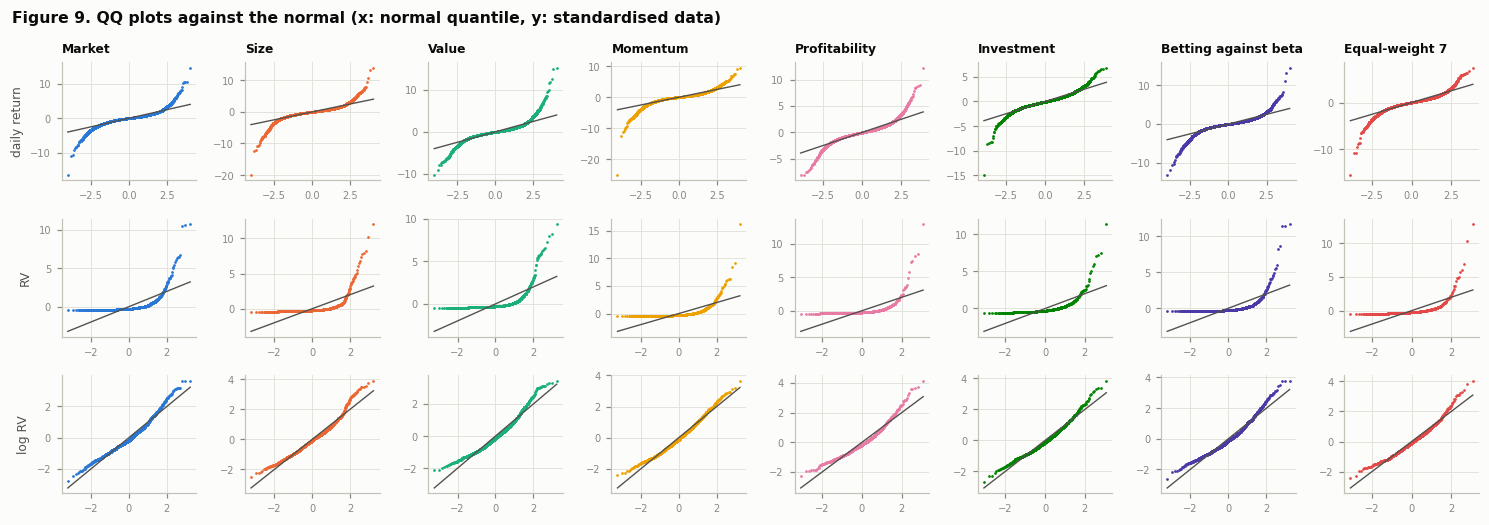

In [39]:
T7 = pd.DataFrame({a: v.t7_moments(R[a], M[a]) for a in v.ASSETS}).T
T7["log RV near normal"] = T7["log RV near normal"].map({True: "yes", False: "no"})
display(T7)

series = [("daily return", lambda a: R[a].dropna()), ("RV", lambda a: M[a]["rv"]), ("log RV", lambda a: M[a]["log_rv"])]
fig, ax = grid(3, 8, w=1.7, h=1.6)
for j, a in enumerate(v.ASSETS):
    for i, (lab, get) in enumerate(series):
        x = get(a); z = (x - x.mean()) / x.std()
        (osm, osr), _ = stats.probplot(z, dist="norm")
        axi = ax[i, j]
        axi.plot(osm, osr, ".", ms=1.6, color=COLORS[a])
        lim = [osm.min(), osm.max()]; axi.plot(lim, lim, color=INK2, lw=0.9)
        axi.tick_params(labelsize=6.5)
        if i == 0: axi.set_title(NAMES[a], fontsize=8)
        if j == 0: axi.set_ylabel(lab, fontsize=8)
fig.suptitle("Figure 9. QQ plots against the normal (x: normal quantile, y: standardised data)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

**Result.**
- **Daily returns are very fat-tailed:** kurtosis 12–31, against 3 for a normal. Monthly returns have kurtosis 5–14. For comparison, Barroso and Santa-Clara report 18.2 for momentum and 7.4 for the market; their decile momentum has fatter tails than French's.
- **RV is extremely right-skewed** (skewness 5–7, kurtosis 34–84). A handful of crisis months dominate any regression in levels, which is the October 1987 problem from Test 6.
- **Log RV is most of the way to normal** (skewness 0.50–0.97, kurtosis 3.0–4.3), but still right-skewed: the top of each QQ plot bends upward, so the worst crisis months are extreme even in logs.
- **Rule verdict:** by the pre-set rule, no asset qualifies. Momentum comes closest (skewness 0.501, kurtosis 3.05).

**Decision.** The "forecast in logs" action is not triggered automatically. Logs are still clearly the better-behaved scale (see also Tests 6 and 9), so Phase 6 should compare log and level forecasts out of sample. When a log forecast is back-transformed it needs a bias correction: $\exp(E[\log RV])$ understates $E[RV]$.

## 11. Test 8 — How collinear are the forecast terms?

**What and why.** The daily, weekly and monthly windows overlap by construction: the monthly average contains the weekly one, which contains today. Collinearity blurs *which* coefficient matters; it barely hurts forecast accuracy, so it limits interpretation, not the strategy. The variance inflation factor of term *j* regresses it on the other terms:
$$VIF_j = \frac{1}{1 - R_j^2}$$
If the other terms explain 90% of the weekly term, $R_j^2 = 0.9$ and VIF = 1/0.1 = 10.

The table also shows the fix the spec suggests: non-overlapping pieces (today, the 4 days before, the 17 days before that).

**Rule.** Any VIF above 10 is severe.

In [40]:
T8 = pd.DataFrame({a: v.t8_vif(R[a]) for a in v.ASSETS}).T
T8["severe"] = T8["severe"].map({True: "yes", False: "no"})
T8

,VIF d,VIF w,VIF m,VIF d (pieces),VIF w_ex,VIF m_ex,severe
mkt,1.591,2.621,1.990,1.156,1.376,1.318,no
smb,1.537,2.446,1.902,1.138,1.307,1.263,no
hml,1.547,2.824,2.262,1.154,1.441,1.454,no
mom,1.412,2.330,1.910,1.077,1.241,1.261,no
rmw,1.858,4.588,3.698,1.381,2.184,2.295,no
cma,1.553,2.857,2.286,1.155,1.452,1.471,no
bab,1.624,3.512,2.858,1.220,1.725,1.803,no
ew7,1.577,3.047,2.457,1.182,1.544,1.580,no


**Result.** VIFs run from 1.4 to 4.6, far below 10. The spec expected high values, but daily $r^2$ is so noisy that its 5-day and 22-day averages are much less correlated than their overlap suggests. The non-overlapping pieces bring the VIFs down to 1.1–2.3.

**Decision.** Use standard HAR terms; no ridge regression is needed. The Test 2 coefficients can be read one by one.

## 12. Test 9 — Linear or nonlinear?

**What and why.** If high-variance months behave differently, for example by being more persistent, a linear model misses it and a nonlinear model (gradient boosting, M7) could help. The plot shows $\log RV_{t+1}$ against $\log RV_t$ with a LOWESS smooth curve, which bends wherever the data bends. Two regression checks follow, with Newey-West errors.

1. A quadratic term:
$$\log RV_{t+1} = a + b\,\log RV_t + c\,(\log RV_t)^2 + e_{t+1}$$
2. A separate slope for the top 20% of variance months.

**Rule.** Nonlinear if *c*, or the top-20% slope shift, has abs t > 1.96.

The real test comes later: does gradient boosting beat HAR out of sample in most folds? Curvature found in-sample that does not survive out of sample is noise.

,c,t_c,slope,slope top 20%,t_shift,nonlinear
mkt,0.037,2.275,0.661,0.873,2.152,yes
smb,0.015,0.843,0.740,0.822,0.790,no
hml,0.043,3.396,0.687,0.886,2.504,yes
mom,0.012,0.675,0.728,0.793,0.470,no
rmw,0.062,4.143,0.607,0.909,3.418,yes
cma,0.042,1.964,0.652,0.819,1.414,yes
bab,0.033,1.942,0.714,0.858,1.322,no
ew7,0.012,0.329,0.641,0.738,0.524,no


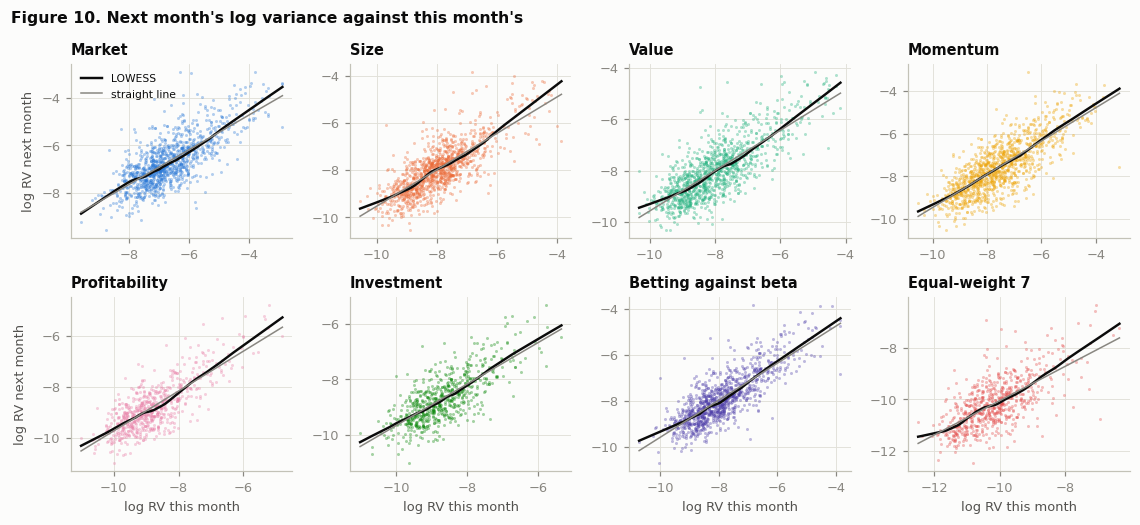

In [41]:
T9 = pd.DataFrame({a: v.t9_curvature(M[a]) for a in v.ASSETS}).T
T9["nonlinear"] = T9["nonlinear"].map({True: "yes", False: "no"})
display(T9)

fig, ax = grid(2, 4, w=2.6, h=2.4)
for a, axi in zip(v.ASSETS, ax.flat):
    x, y = M[a]["log_rv"].iloc[:-1].to_numpy(), M[a]["log_rv"].iloc[1:].to_numpy()
    axi.scatter(x, y, s=4, color=COLORS[a], alpha=0.35, lw=0)
    sm_ = lowess(y, x, frac=0.3)
    axi.plot(sm_[:, 0], sm_[:, 1], color=INK, lw=1.6, label="LOWESS")
    b = np.polyfit(x, y, 1); xs = np.array([x.min(), x.max()])
    axi.plot(xs, b[1] + b[0] * xs, color=MUTED, lw=1.0, label="straight line")
    axi.set_title(NAMES[a])
ax[0, 0].legend(loc="upper left", fontsize=7)
for axi in ax[1]: axi.set_xlabel("log RV this month")
for axi in ax[:, 0]: axi.set_ylabel("log RV next month")
fig.suptitle("Figure 10. Next month's log variance against this month's", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

**Result.**
- **Nonlinear:** market, value, profitability and investment.
- **The shape:** wherever curvature is present it is convex (*c* > 0). Persistence is stronger in high-variance months: the slope in the top 20% is 0.82–0.91, against 0.61–0.69 overall. Turbulent spells last longer than ordinary fluctuations, and the LOWESS curve bends upward at the right of those panels.
- **Linear:** momentum, size, BAB and the equal-weight portfolio show no significant curvature.

**Decision.** M7 (gradient boosting) stays a candidate for market, value, profitability and investment, to be judged out of sample. For the other four the rule drops it.

## 13. Test 10 — How much does history help, and how much data is enough?

### Part A — How far back

Lags are added in stages: 1 day, 1–5, 1–22, 1–66. Each stage adds the *average* over a longer window, as in the HAR, instead of every lag separately. That uses the same information without estimating 66 coefficients.

The target is the next 22 days' average variance. The **out-of-sample** R² is computed on an expanding window, refit each January using only days whose 22-day target was fully known before that January. The first 10 years are the initial training window. The benchmark is the expanding mean of the target.

**Rule.** History helps until a stage adds less than 0.5 point of out-of-sample R².

,OOS R² 1 day,OOS R² 1-5 days,OOS R² 1-22 days,OOS R² 1-66 days,gain from 1-5 days,gain from 1-22 days,gain from 1-66 days
mkt,0.123,0.288,0.393,0.411,0.165,0.106,0.018
smb,0.040,0.108,0.245,0.289,0.068,0.137,0.044
hml,0.161,0.393,0.559,0.614,0.232,0.166,0.054
mom,0.024,0.151,0.276,0.336,0.127,0.125,0.060
rmw,0.129,0.340,0.521,0.532,0.211,0.180,0.011
cma,0.101,0.291,0.453,0.500,0.190,0.162,0.047
bab,0.217,0.519,0.611,0.629,0.302,0.093,0.018
ew7,0.122,0.262,0.319,0.386,0.141,0.057,0.066


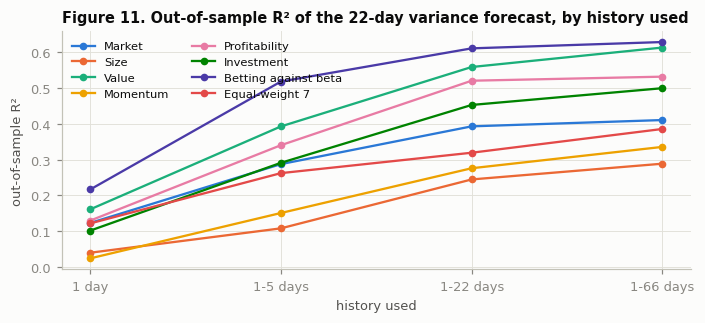

In [42]:
T10A = pd.DataFrame({a: v.t10_oos_stages(R[a]) for a in v.ASSETS}).T
gain = T10A.diff(axis=1).iloc[:, 1:].add_prefix("gain from ")
display(pd.concat([T10A.add_prefix("OOS R² "), gain], axis=1))

fig, axi = plt.subplots(figsize=(6.5, 3.0))
for a in v.ASSETS:
    axi.plot(range(4), T10A.loc[a], marker="o", ms=4, color=COLORS[a], label=NAMES[a])
axi.set_xticks(range(4), [f"{k}" for k in v.STAGES]); axi.set_xlabel("history used")
axi.set_ylabel("out-of-sample R²"); axi.legend(loc="upper left", ncol=2, fontsize=7.5)
axi.set_title("Figure 11. Out-of-sample R² of the 22-day variance forecast, by history used")
fig.tight_layout()

**Result.** Out-of-sample R² rises at every stage for every asset. Going from 22 to 66 days still adds 1.1–6.6 points, well above the 0.5-point threshold. History helps for at least a quarter.

**Decision.** Add a 66-day (quarterly) average to the HAR terms.

### Part B — How much data before estimates settle

For a monthly AR(1), the standard error of the slope is roughly
$$SE(\hat{\phi}) \approx \sqrt{\frac{1 - \phi^2}{n}}$$
With φ = 0.7 and n = 120 months, SE ≈ 0.065, so the 95% band is about ±0.13 (φ between roughly 0.57 and 0.83). With n = 60 the band widens to ±0.18. This backs the 10-year initial training window.

Below: the rolling 10-year φ against the band it should stay in if φ were constant, the rolling 10-year mean of log RV, and a CUSUM test for a shift in that mean. The CUSUM uses a Newey-West long-run variance, so persistence alone is not mistaken for a break.

**Rule.** φ drifts if the rolling φ is outside its 95% band in more than 20% of windows; a mean break exists if the CUSUM rejects at 5%.

,"95% half-band, n = 60 months","95% half-band, n = 120 months","95% half-band, n = 240 months"
φ = 0.5,0.219,0.155,0.110
φ = 0.7,0.181,0.128,0.090


,phi (full),share of windows outside band,CUSUM stat,CUSUM p,most likely break,drift or break
mkt,0.621,0.487,1.675,0.007,1940-11,yes
smb,0.595,0.692,1.771,0.004,1942-01,yes
hml,0.726,0.701,2.264,0.000,1945-08,yes
mom,0.535,0.485,1.847,0.002,1947-07,yes
rmw,0.761,0.768,2.394,0.000,1998-07,yes
cma,0.681,0.344,1.255,0.086,1995-05,yes
bab,0.668,0.571,1.558,0.016,1947-10,yes
ew7,0.604,0.804,2.541,0.000,1998-08,yes


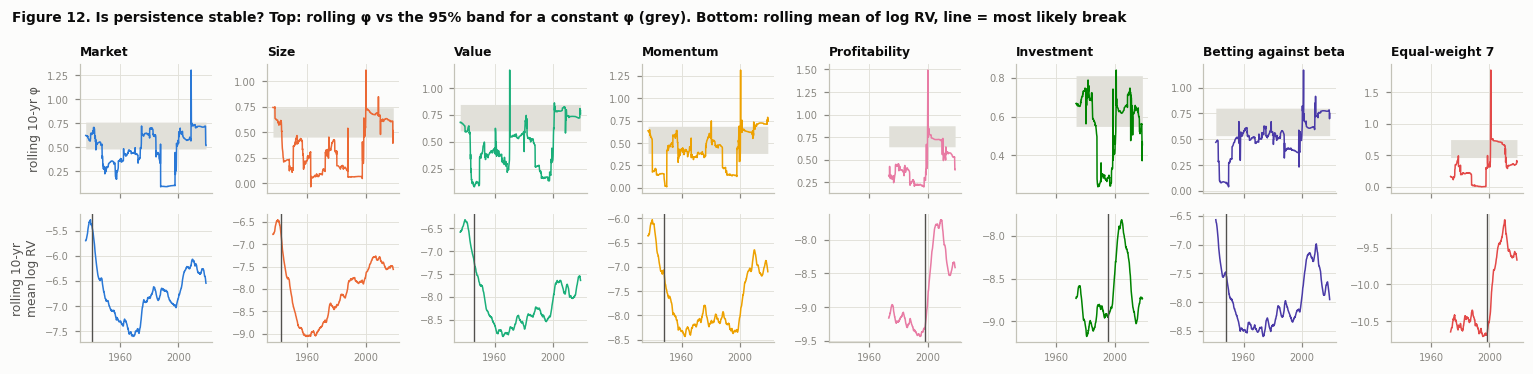

In [43]:
display(pd.DataFrame({n: {f"φ = {p}": 1.96 * v.se_phi(p, n) for p in (0.5, 0.7)} for n in (60, 120, 240)})
          .rename(columns=lambda n: f"95% half-band, n = {n} months"))

T10B = pd.DataFrame({a: {"phi (full)": T1.loc[a, "phi"],
                         "share of windows outside band": v.drift_share(M[a], T1.loc[a, "phi"]),
                         **v.cusum_mean(M[a]["log_rv"])} for a in v.ASSETS}).T
T10B["drift or break"] = ((T10B["share of windows outside band"] > v.RULES["t10_drift_share"])
                          | (T10B["p"] < 0.05)).map({True: "yes", False: "no"})
T10B["most likely break"] = T10B["most likely break"].astype(str)
display(T10B.rename(columns={"stat": "CUSUM stat", "p": "CUSUM p"}))

fig, ax = grid(2, 8, w=1.75, h=1.7, sharex=True)
for j, a in enumerate(v.ASSETS):
    rp = v.rolling_phi(M[a]); phi = T1.loc[a, "phi"]; band = 1.96 * v.se_phi(min(phi, 0.99), 120)
    t = rp.index.to_timestamp()
    ax[0, j].fill_between(t, phi - band, phi + band, color=GRID, lw=0)
    ax[0, j].plot(t, rp, color=COLORS[a], lw=1)
    ax[0, j].set_title(NAMES[a], fontsize=8)
    lm = M[a]["log_rv"].rolling(120).mean()
    ax[1, j].plot(lm.index.to_timestamp(), lm, color=COLORS[a], lw=1)
    ax[1, j].axvline(pd.Period(T10B.loc[a, "most likely break"], "M").to_timestamp(), color=INK2, lw=0.9)
    for axi in ax[:, j]:
        axi.tick_params(labelsize=6.5); axi.xaxis.set_major_locator(mdates.YearLocator(40))
        axi.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax[0, 0].set_ylabel("rolling 10-yr φ", fontsize=8); ax[1, 0].set_ylabel("rolling 10-yr\nmean log RV", fontsize=8)
fig.suptitle("Figure 12. Is persistence stable? Top: rolling φ vs the 95% band for a constant φ (grey). "
             "Bottom: rolling mean of log RV, line = most likely break", x=0.01, ha="left", fontweight="bold", fontsize=9)
fig.tight_layout()

**Result.**
- **Rolling φ wanders far more than sampling noise allows.** It sits outside its band in 34–80% of windows; with a constant φ that share would be about 5%. It also jumps whenever a spike month enters or leaves the window (1987 again).
- **Mean log variance has breaks.** The CUSUM rejects a stable mean for 7 of 8 assets; only investment does not (p = 0.09). The most likely breaks are in the 1940s for the long series, the end of the high-variance 1930s and 1940s, and 1995–1998 for the series starting in 1963, when factor volatility rose in the late 1990s.
- **Caveat:** persistent series make break tests reject easily. Read the CUSUM together with the rolling plots, which show the same thing.

**Decision.** Use rolling as well as expanding estimation windows, and re-screen model choices every year. Test 6 already showed the era dependence.

### Part C — The ceiling

A plain monthly AR(1) on RV, in-sample and out of sample (expanding window from 10 years, refit monthly, against the historical mean). Barroso and Santa-Clara, 1927–2011: market 36% in-sample and 39% out of sample; momentum 49% and 58%.

In [44]:
T10C = pd.DataFrame({a: {"AR(1) R² in-sample": T1.loc[a, "R2"], "AR(1) R² out-of-sample": v.ar1_oos(M[a]),
                         "daily HAR (1-66 days) OOS R², 22-day target": T10A.loc[a, "1-66 days"]}
                     for a in v.ASSETS}).T
T10C

,AR(1) R² in-sample,AR(1) R² out-of-sample,"daily HAR (1-66 days) OOS R², 22-day target"
mkt,0.385,0.370,0.411
smb,0.354,0.158,0.289
hml,0.526,0.578,0.614
mom,0.287,0.210,0.336
rmw,0.579,0.357,0.532
cma,0.464,0.425,0.500
bab,0.446,0.578,0.629
ew7,0.365,0.277,0.386


**Result.**
- **Market:** 38% in-sample and 37% out of sample, in line with Barroso and Santa-Clara's 36% and 39%.
- **Momentum:** 29% and 21%, well below their 49% and 58%. Their decile momentum has more extreme, more predictable crash spells than French's.
- **Overall:** a monthly AR(1) explains 16–58% out of sample. The daily HAR with 66 days of history explains 29–63% of the 22-day target. History explains roughly a third to a half of next month's variance; the rest is new shocks.

**Decision.** These are the numbers to beat. A fancier model only matters if it beats the simple one out of sample. If it does not, stop at EWMA or HAR and spend the effort on the scaling constant $c_t$ and the portfolio weights.

## 14. ETFs — Is the high-low range a better daily variance input?

**What and why.** For daily models on ETFs, Parkinson's range estimator should be far less noisy than $r^2$. The check: forecast the next 22 days' mean $r^2$ with HAR terms built from $r^2$, then from Parkinson, and compare the R² over development years only. The Phase 2 spec gives no pass rule here, so this section is descriptive.

In [45]:
E = pd.DataFrame({t: v.proxy_comparison(panel[t.lower()], v.parkinson(ohlc_dev, t)) for t in ETFS}).T
E.insert(0, "first day", [str(ohlc_dev.loc[ohlc_dev.ticker == t, "date"].min().date()) for t in ETFS])
display(E)

# Explanation check (added after seeing the result): the largest daily ranges of each ETF.
rows = []
for t in ETFS:
    p = v.parkinson(ohlc_dev, t)
    for day, x in p.nlargest(2).items():
        rows.append({"ETF": t, "date": day.date(), "range-implied daily move, %": np.sqrt(x) * 100,
                     "close-to-close move, %": abs(panel.loc[day, t.lower()]) * 100})
pd.DataFrame(rows).set_index("ETF")

,first day,R2 HAR (r²),R2 HAR (Parkinson),Parkinson / r² mean
SPY,1993-01-29,0.454,0.497,0.728
MTUM,2013-04-18,0.191,0.072,0.874
QUAL,2013-07-18,0.137,0.034,1.254
USMV,2011-10-20,0.088,0.038,1.521


,date,"range-implied daily move, %","close-to-close move, %"
ETF,,,
SPY,2008-10-13,7.166,14.520
SPY,2008-10-10,7.018,2.426
MTUM,2015-08-24,13.392,3.960
MTUM,2013-08-19,8.005,0.171
QUAL,2015-08-24,23.477,3.819
QUAL,2013-08-22,4.275,0.766
USMV,2015-08-24,25.336,3.752
USMV,2011-12-12,6.358,1.406


**Result.**
- **SPY: the range works as theory says.** R² is 0.50 with Parkinson against 0.45 with $r^2$.
- **MTUM, QUAL and USMV: the range is much worse.** R² is 0.07 vs 0.19, 0.03 vs 0.14 and 0.04 vs 0.09. For QUAL and USMV the range estimate is even larger on average than $r^2$.
- **Explanation check, added after seeing this:**
  - **24 August 2015.** The largest ranges fall on that day. At the open, many ETFs traded far below the value of their holdings for several minutes. USMV's range implies a 25% daily move, against a close-to-close move of 3.75%. These were real trades, not data errors.
  - **Thin early trading.** Volume in each fund's first year was thin (median 7,700–25,000 shares a day), so early ranges partly measure bid-ask noise. SPY is deep and liquid.

**Decision.**
- **SPY:** Parkinson for daily models.
- **MTUM, QUAL, USMV:** $r^2$ for now, or a range estimator that guards against dislocations, such as capping each day's range at a multiple of |r|. Revisit in the implementation phase.
- **For the cost work:** trading these ETFs at the open on a day like 24 August 2015 would have been very costly.

## 15. What each finding changes

All ten tests feed Phase 6 (model choice). The table collects every verdict, computed from the rules above, and the findings table below it maps each finding onto the model or later phase it changes.

In [46]:
summary = pd.DataFrame({
    "T1 predictable (gate)": T1["pass"],
    "T2 memory": T2["verdict"],
    "T3 bad days raise risk": T3["pass"],
    "T4 reward falls with risk": T4["pass"],
    "T5 VIX adds info": T5["pass"],
    "T5 any event day": pd.Series({a: "pass" if EV[a]["pass"].any() else "fail" for a in v.ASSETS}),
    "T6 eras consistent (of 4)": T6c.sum(axis=1).astype(int),
    "T7 log RV near normal": T7["log RV near normal"],
    "T8 severe collinearity": T8["severe"],
    "T9 nonlinear": T9["nonlinear"],
    "T10 drift or break": T10B["drift or break"],
})
summary.index = [NAMES[a] for a in summary.index]
summary

,T1 predictable (gate),T2 memory,T3 bad days raise risk,T4 reward falls with risk,T5 VIX adds info,T5 any event day,T6 eras consistent (of 4),T7 log RV near normal,T8 severe collinearity,T9 nonlinear,T10 drift or break
Market,pass,long memory,fail,pass,pass,fail,2,no,no,yes,yes
Size,pass,long memory,fail,fail,fail,fail,1,no,no,no,yes
Value,pass,long memory,pass,fail,pass,fail,2,no,no,yes,yes
Momentum,pass,short memory,fail,pass,pass,fail,3,no,no,no,yes
Profitability,pass,long memory,fail,fail,fail,fail,3,no,no,yes,yes
Investment,pass,short memory,fail,fail,fail,fail,3,no,no,yes,yes
Betting against beta,pass,long memory,fail,pass,pass,fail,4,no,no,no,yes
Equal-weight 7,pass,long memory,fail,pass,fail,fail,1,no,no,no,yes


| Finding | Assets | Action in later phases |
|---|---|---|
| Variance is predictable (gate) | all 8 | all stay timing candidates |
| Slow decay; weekly and monthly terms matter; 66 days still help out of sample | 6 of 8 by the rule, all 8 out of sample | **HAR family with a 66-day term**. Skip plain GARCH as the main model; keep EWMA/GARCH as the benchmark, especially for momentum and investment |
| Reward per unit of risk falls with risk | market, momentum, BAB, ew7 (value, profitability borderline) | **time these**; hold size and investment at constant weight |
| Bad days predict more variance | value only (market through returns) | downside HAR / GJR-GARCH only for value and the market |
| VIX adds information | market, value, momentum, BAB | **HAR-X (VIX)** for these four in Phase 6 |
| Event days have higher variance | none | no event flags |
| Log RV much closer to normal, short of the rule | all 8 | forecast in **logs and levels**, choose out of sample; bias-correct log forecasts |
| Curvature | market, value, profitability, investment | keep M7 for these only; drop it if boosting loses out of sample |
| High VIF | none | standard HAR terms, no ridge |
| Drifting φ; breaks in mean log RV | all 8 drift; 7 of 8 have breaks | **rolling windows, yearly re-screening**, check across eras |
| History explains 15–60% out of sample | all | if fancy ≈ simple out of sample, stop at EWMA/HAR and spend the effort on $c_t$ and weights |

### Caveats

- **In-sample screens.** Test 4's alpha and Test 9's curvature are in-sample. Only the walk-forward phases can confirm them.
- **Many verdicts.** About 80 verdicts, so read the consistent patterns, not single p-values. The strongest are: persistence everywhere; long memory everywhere; falling reward-to-risk for market, momentum and BAB in every era; VIX for market, momentum and BAB.
- **Equal-weight 7 is a placeholder.** Its weights are not the strategy's.
- **Level vs log.** Several level-based results (φ by era, the drift share) are driven by single spike months. Their log versions are steadier.